# Vanilla Option Pricing: Black-Scholes, Greeks, Implied Volatility and Binomial Trees

**Goal.** Build, from first principles, the toolkit every derivatives desk uses daily:
a closed-form pricer, its sensitivities (the Greeks), an implied-volatility solver and a
binomial tree for American options, then check each piece against the others.

**Why it matters.** Pricing and hedging start here. Structured products, volatility
surfaces and risk engines (other projects in this portfolio) are built on these functions.

| Section | What it shows |
|---|---|
| 1. Black-Scholes | Price profile and put-call parity |
| 2. Greeks | Delta, gamma, vega, theta across spot and maturity |
| 3. Implied volatility | Newton-Raphson solver, round-trip accuracy |
| 4. Binomial tree | Convergence to Black-Scholes, American early exercise |

In [1]:
# Google Colab: fetch the project files (does nothing when run locally)
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("options.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/01-options-pricing")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from options import bs_price, bs_greeks, implied_vol, binomial_price

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"

## 1. Black-Scholes-Merton

Under the risk-neutral measure the stock follows $dS_t = (r-q)S_t\,dt + \sigma S_t\,dW_t$.
The price of a European call with strike $K$ and maturity $T$ is

$$C = S e^{-qT} N(d_1) - K e^{-rT} N(d_2), \qquad
d_{1,2} = \frac{\ln(S/K) + (r - q \pm \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}$$

and the put follows from **put-call parity**: $C - P = S e^{-qT} - K e^{-rT}$.

ATM 1y call = 8.8273   put = 6.8669
Put-call parity gap = 0.00e+00


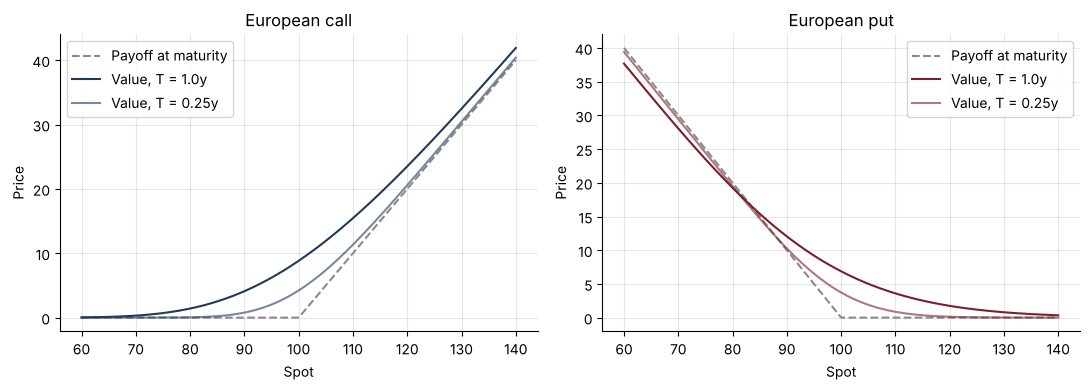

In [2]:
S0, K, T, r, sigma, q = 100.0, 100.0, 1.0, 0.03, 0.20, 0.01
call, put = bs_price(S0, K, T, r, sigma, q, "call"), bs_price(S0, K, T, r, sigma, q, "put")
print(f"ATM 1y call = {call:.4f}   put = {put:.4f}")
print(f"Put-call parity gap = {call - put - (S0*np.exp(-q*T) - K*np.exp(-r*T)):.2e}")

spots = np.linspace(60, 140, 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, opt, color in zip(axes, ["call", "put"], [NAVY, BORDEAUX]):
    payoff = np.maximum(spots - K, 0) if opt == "call" else np.maximum(K - spots, 0)
    ax.plot(spots, payoff, color=GREY, ls="--", label="Payoff at maturity")
    for t, a in [(1.0, 1.0), (0.25, 0.6)]:
        ax.plot(spots, bs_price(spots, K, t, r, sigma, q, opt), color=color, alpha=a, label=f"Value, T = {t}y")
    ax.set(title=f"European {opt}", xlabel="Spot", ylabel="Price")
    ax.legend()
plt.tight_layout(); plt.savefig("images/price_profiles.png", dpi=150); plt.show()

## 2. The Greeks

The Greeks measure how the option value moves with each market input. A trader hedges
**delta** with the underlying, while **gamma** and **vega** drive the P&L of that hedge.

| Greek | Definition | Call formula |
|---|---|---|
| Delta | $\partial V/\partial S$ | $e^{-qT}N(d_1)$ |
| Gamma | $\partial^2 V/\partial S^2$ | $e^{-qT}\varphi(d_1)/(S\sigma\sqrt{T})$ |
| Vega | $\partial V/\partial \sigma$ | $S e^{-qT}\varphi(d_1)\sqrt{T}$ |
| Theta | $\partial V/\partial t$ | time decay per year |
| Rho | $\partial V/\partial r$ | $K T e^{-rT} N(d_2)$ |

The tests in `test_options.py` check every analytical formula against finite differences.

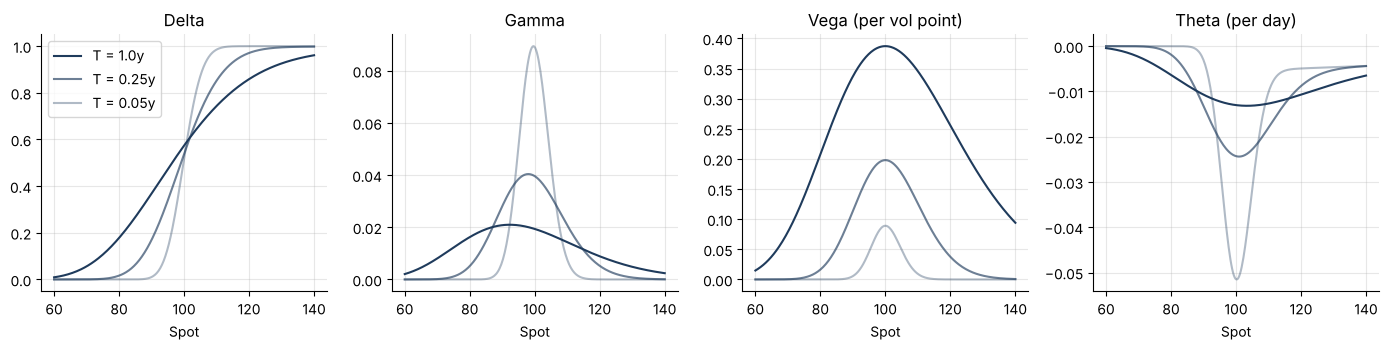

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for t, a in [(1.0, 1.0), (0.25, 0.65), (0.05, 0.35)]:
    g = bs_greeks(spots, K, t, r, sigma, q, "call")
    for ax, name in zip(axes, ["delta", "gamma", "vega", "theta"]):
        scale = 1 / 100 if name == "vega" else (1 / 365 if name == "theta" else 1)
        ax.plot(spots, g[name] * scale, color=NAVY, alpha=a, label=f"T = {t}y")
units = {"delta": "", "gamma": "", "vega": " (per vol point)", "theta": " (per day)"}
for ax, name in zip(axes, ["delta", "gamma", "vega", "theta"]):
    ax.set(title=name.capitalize() + units[name], xlabel="Spot")
axes[0].legend()
plt.tight_layout(); plt.savefig("images/greeks.png", dpi=150); plt.show()

**Reading the chart.** As maturity shortens, delta turns into a step function and gamma
concentrates around the strike: an at-the-money option close to expiry is the hardest
to hedge. Vega is highest for long-dated at-the-money options, and theta is the price
paid every day for holding gamma.

In [4]:
greeks_table = pd.DataFrame({k: bs_greeks(S0, K, T, r, sigma, q, opt) for k, opt in
                             [("Call", "call"), ("Put", "put")]}).T
greeks_table["vega"] /= 100; greeks_table["theta"] /= 365; greeks_table["rho"] /= 100
greeks_table.columns = ["Delta", "Gamma", "Vega (1 vol pt)", "Theta (1 day)", "Rho (1%)"]
greeks_table.round(4)

,Delta,Gamma,Vega (1 vol pt),Theta (1 day),Rho (1%)
Call,0.5735,0.0194,0.3872,-0.0130,0.4852
Put,-0.4166,0.0194,0.3872,-0.0078,-0.4852


## 3. Implied volatility

Markets quote options in volatility, not in price. Inverting Black-Scholes has no closed
form, so `implied_vol` uses **Newton-Raphson** ($\sigma_{n+1} = \sigma_n - (BS(\sigma_n) - P)/\text{vega}$),
which converges in a handful of iterations, with a **Brent** fallback when vega is too
small (deep in- or out-of-the-money options).

In [5]:
rows = []
for strike in [60, 80, 100, 120, 160]:
    for vol in [0.10, 0.35, 0.80]:
        price = bs_price(S0, strike, T, r, vol, q, "call")
        rows.append({"Strike": strike, "True vol": vol, "Price": price,
                     "Recovered vol": implied_vol(price, S0, strike, T, r, q, "call")})
iv = pd.DataFrame(rows)
iv["Error"] = (iv["Recovered vol"] - iv["True vol"]).abs()
print(f"Max round-trip error over {len(iv)} cases: {iv['Error'].max():.1e}")
iv.head(6).round(6)

Max round-trip error over 15 cases: 8.6e-07


,Strike,True vol,Price,Recovered vol,Error
0,60,0.10,40.778251,0.100001,0.000001
1,60,0.35,41.519694,0.350000,0.000000
2,60,0.80,49.606145,0.800000,0.000000
3,80,0.10,21.391004,0.100000,0.000000
4,80,0.35,25.755128,0.350000,0.000000
5,80,0.80,39.323805,0.800000,0.000000


## 4. Binomial tree and American options

The Cox-Ross-Rubinstein tree moves the stock up by $u = e^{\sigma\sqrt{\Delta t}}$ or down by
$d = 1/u$, with risk-neutral probability $p = (e^{(r-q)\Delta t} - d)/(u-d)$. Rolling back
through the tree, an American option takes at each node the maximum of its continuation
value and its exercise value.

**Check 1:** for a European option the tree must converge to Black-Scholes.

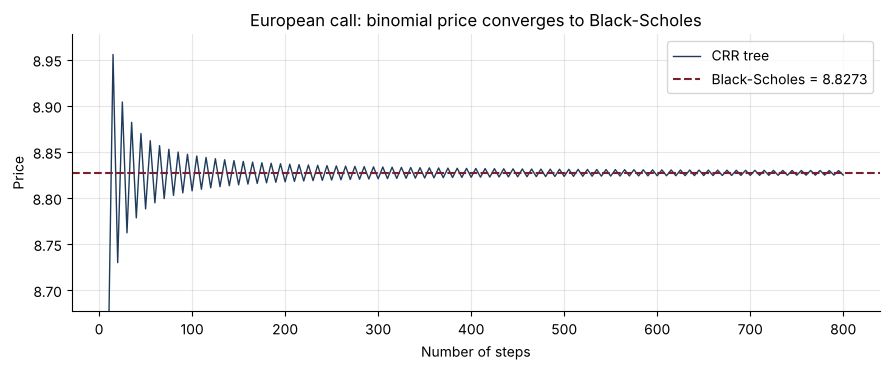

Error at 800 steps: 0.00245


In [6]:
steps = np.arange(10, 801, 5)
tree = [binomial_price(S0, K, T, r, sigma, q, "call", american=False, steps=n) for n in steps]
plt.figure(figsize=(9, 3.8))
plt.plot(steps, tree, color=NAVY, lw=1, label="CRR tree")
plt.axhline(call, color=BORDEAUX, ls="--", label=f"Black-Scholes = {call:.4f}")
plt.ylim(call - 0.15, call + 0.15)
plt.title("European call: binomial price converges to Black-Scholes")
plt.xlabel("Number of steps"); plt.ylabel("Price"); plt.legend()
plt.tight_layout(); plt.savefig("images/convergence.png", dpi=150); plt.show()
print(f"Error at 800 steps: {abs(tree[-1] - call):.5f}")

**Check 2:** an American put is worth more than its European twin because early exercise
can be optimal: once the put is deep in the money, receiving $K$ today and earning
interest beats waiting. The tree also gives the **early-exercise boundary**, the stock
price below which the holder should exercise.

American put = 5.7982   European put = 5.1660   early-exercise premium = 0.6322


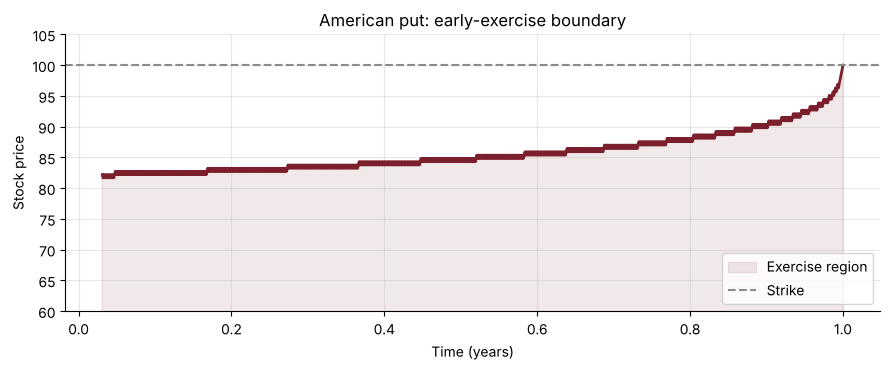

In [7]:
r_high = 0.06
am, times, boundary = binomial_price(S0, K, T, r_high, sigma, 0.0, "put", american=True,
                                      steps=1000, return_boundary=True)
eu = bs_price(S0, K, T, r_high, sigma, 0.0, "put")
print(f"American put = {am:.4f}   European put = {eu:.4f}   early-exercise premium = {am - eu:.4f}")

plt.figure(figsize=(9, 3.8))
plt.plot(times, boundary, color=BORDEAUX, lw=2)
plt.fill_between(times, 0, boundary, color=BORDEAUX, alpha=0.1, label="Exercise region")
plt.axhline(K, color=GREY, ls="--", label="Strike")
plt.ylim(60, 105); plt.xlabel("Time (years)"); plt.ylabel("Stock price")
plt.title("American put: early-exercise boundary"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("images/exercise_boundary.png", dpi=150); plt.show()

## Conclusions

- The closed-form pricer, analytical Greeks and implied-vol solver agree with finite
  differences and with each other to machine precision (see `test_options.py`).
- The binomial tree converges to Black-Scholes with the expected oscillation in $1/n$,
  and it prices the early-exercise premium that closed formulas cannot capture.
- **Next steps:** add discrete dividends, a trinomial tree, and the volatility smile
  (project 03).